# Part 1 — The Chiarella model and its stylized facts

**Question.** What can the modified Chiarella model produce, and does it look like a real market?

**Model.** Two types of agents trade one asset: **chartists** follow the trend $m_t$ (exponential moving average of returns) and **fundamentalists** pull the price towards a fundamental value $v_t$ (exponential moving average of prices):

$$r_{t+1} = \kappa\big[(v_t-p_t)^3-(v_{t-1}-p_{t-1})^3\big] + \beta\big[\tanh(\gamma m_t)-\tanh(\gamma m_{t-1})\big] + \varepsilon_{t+1}.$$

**Outline.**
1. **1.1** Simulator and sanity check.
2. **1.2** Model regimes: trajectories, autocorrelations, return distribution, and three maps of fat tails, volatility clustering and explosions.
3. **1.3** Comparison with the S&P 500 (daily, weekly, monthly).

**Requires** `abm.py`, `data/sp500_daily.csv`. Runtime: about 5 minutes (the three maps).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

## 1.1 Parameters and simulator

In [2]:
# Reference parameters from the group project slides (defined in abm.py, shared by all notebooks)
from abm import theta0

theta0

{'beta': 0.05,
 'kappa': 0.05,
 'gamma': 10.0,
 'alpha': 0.1,
 'lam': 0.02,
 'sigma': 0.003}

**The simulator.** At each step t, the state (m_t, v_t) is updated from p_t, **then** p_{t+1} is computed. (I fixed a bug of the original group code, which updated v_t after p_{t+1}.) The first 500 steps (*burn-in*) are dropped, as they depend on the arbitrary initial state. If the price diverges (|p| > 10³), the rest of the path is set to NaN.

In [3]:
# The simulator is defined in abm.py; its source is printed here for reading
import inspect

from abm import chiarella

print(inspect.getsource(chiarella))

def chiarella(beta, kappa, gamma, alpha, lam, sigma, T, rng, burn_in=500):
    """Simulate the modified Chiarella model (plain Python: slow but readable).

    Returns (p, m, v): log-price, trend, fundamental value, of length T
    (the first burn_in steps are discarded). If the price diverges, the rest is NaN.
    """
    n = T + burn_in
    p, m, v = np.zeros(n), np.zeros(n), np.zeros(n)
    eps = rng.normal(0.0, sigma, n)

    for t in range(1, n):
        # 1) update the state from p_t ...
        m[t] = (1 - alpha) * m[t - 1] + alpha * (p[t] - p[t - 1])
        v[t] = (1 - lam) * v[t - 1] + lam * p[t]
        if t == n - 1:  # last step: the state is up to date, no p_{t+1} to compute
            break
        # 2) ... then compute p_{t+1}
        fundamentalists = kappa * ((v[t] - p[t]) ** 3 - (v[t - 1] - p[t - 1]) ** 3)
        chartists = beta * (np.tanh(gamma * m[t]) - np.tanh(gamma * m[t - 1]))
        p[t + 1] = p[t] + fundamentalists + chartists + eps[t + 1]

        if not 

**First simulation at `theta0`.** The price fluctuates around the fundamental value, which follows it with a lag (memory ≈ 1/λ = 50 steps). The trend m_t stays tiny: at `theta0`, the deterministic part of the model is negligible compared with the noise.

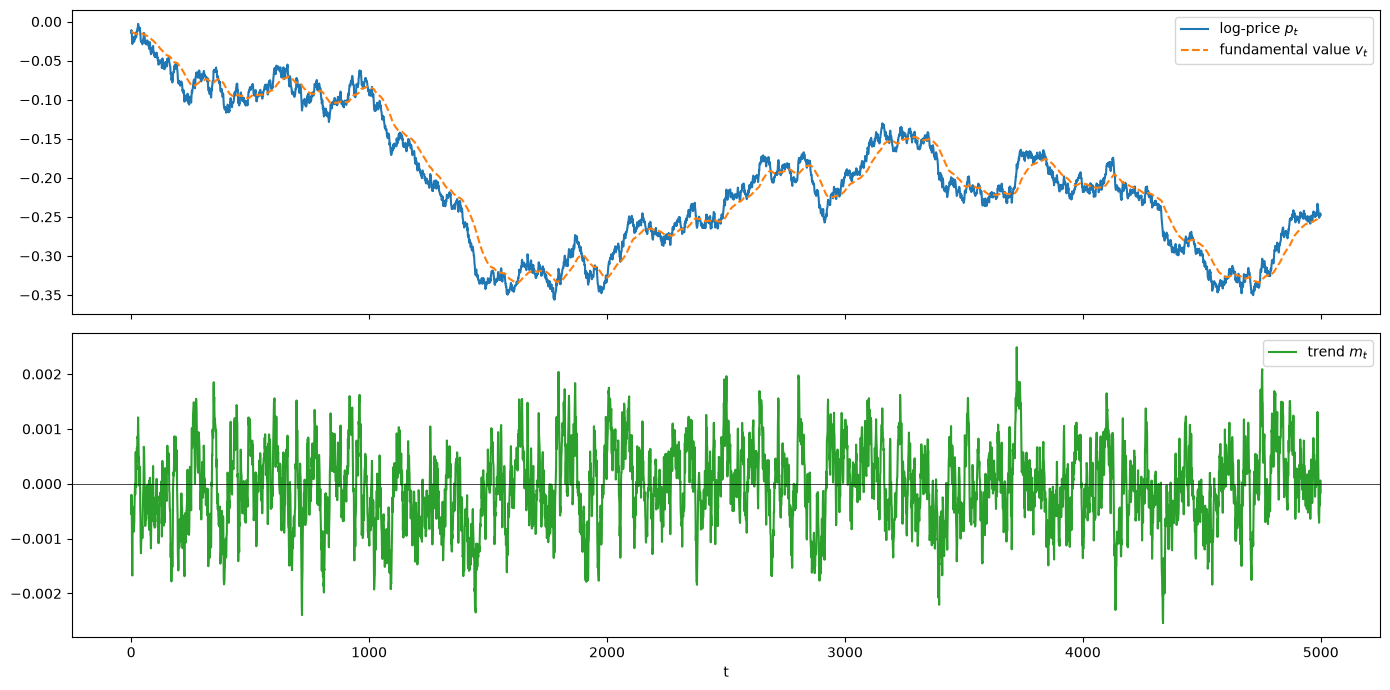

In [4]:
p, m, v = chiarella(**theta0, T=5000, rng=rng)
r = np.diff(p)  # log-returns

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
ax1.plot(p, label="log-price $p_t$")
ax1.plot(v, "--", label="fundamental value $v_t$")
ax1.legend()
ax2.plot(m, color="tab:green", label="trend $m_t$")
ax2.axhline(0, color="black", linewidth=0.5)
ax2.set_xlabel("t")
ax2.legend()
plt.tight_layout()
plt.show()

### Sanity check

With κ = β = 0 the model reduces to a **random walk**: returns are the noise ε, so their standard deviation must equal σ = 0.003 and their autocorrelations must vanish (within the confidence band).

In [5]:
p_rw, _, _ = chiarella(**{**theta0, "beta": 0, "kappa": 0}, T=5000, rng=rng)
r_rw = np.diff(p_rw)
print("std of returns:", np.std(r_rw))

from statsmodels.tsa.stattools import acf as acf_sm
print(acf_sm(r_rw, nlags=3))   # [1, ρ(1), ρ(2), ρ(3)]

std of returns: 0.003029548347807905
[ 1.         -0.00439189  0.00675457 -0.03291922]


## 1.2 Model regimes

**Reference simulation for the summary figure.** `acf_list(x, max_lag)` returns the autocorrelation for all lags from 0 to `max_lag`. `theta1` is `theta0` with a ten times smaller κ: since fundamentalists are already negligible at `theta0`, the result is almost the same.

In [6]:
theta1 = {**theta0, "kappa": 0.005}

p, m, v = chiarella(**theta1, T=5000, rng=rng)
r = np.diff(p)


def acf_list(x, max_lag):
    xm = np.mean(x)
    return [np.dot(x[:len(x) - k] - xm, x[k:] - xm) / (len(x) * np.var(x)) for k in range(max_lag + 1)]

**Summary figure**: price and fundamental value, trend, returns, autocorrelations of r, |r| and r², and return distribution (log scale) against a Gaussian with the same variance.

- **Confidence band ±1.96/√T**: for independent returns, each sample autocorrelation is ≈ N(0, 1/T), so it stays in the band with 95 % probability (about 1 lag in 20 leaves it by chance).
- **Expected at `theta0`**: near Gaussian white noise; only the lag-1 autocorrelation of r is slightly positive, ≈ βγα = 0.05 (the chartists' small momentum).

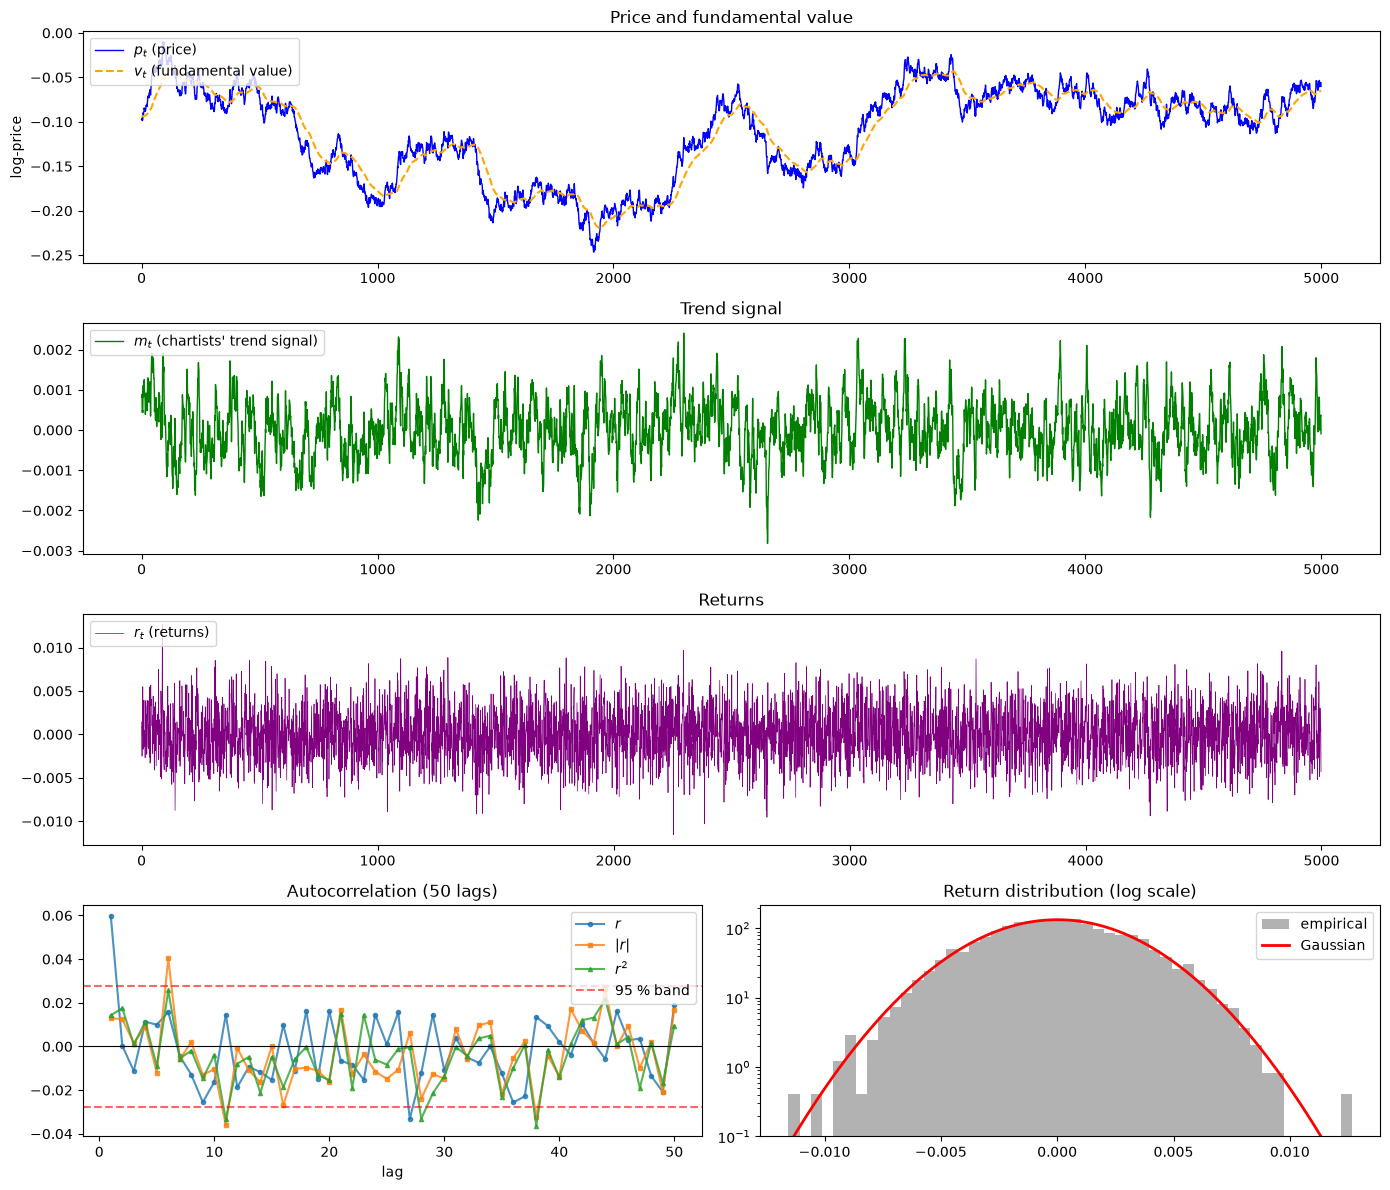

In [7]:
from scipy.stats import norm


def plot_chiarella_results(p, v, m, r, lags=50):
    conf_band = 1.96 / np.sqrt(len(r))
    fig = plt.figure(figsize=(14, 12))

    ax1 = fig.add_subplot(4, 1, 1)
    ax1.plot(p, label="$p_t$ (price)", color="blue", linewidth=1)
    ax1.plot(v, label="$v_t$ (fundamental value)", color="orange", linestyle="--", linewidth=1.5)
    ax1.set_title("Price and fundamental value")
    ax1.set_ylabel("log-price")
    ax1.legend(loc="upper left")

    ax2 = fig.add_subplot(4, 1, 2)
    ax2.plot(m, label="$m_t$ (chartists' trend signal)", color="green", linewidth=1)
    ax2.set_title("Trend signal")
    ax2.legend(loc="upper left")

    ax3 = fig.add_subplot(4, 1, 3)
    ax3.plot(r, label="$r_t$ (returns)", color="purple", linewidth=0.5)
    ax3.set_title("Returns")
    ax3.legend(loc="upper left")

    ax4 = fig.add_subplot(4, 2, 7)
    x_lags = np.arange(1, lags + 1)   # lag 0 removed for readability
    for series, label, marker in [(r, "$r$", "o"), (np.abs(r), "$|r|$", "s"), (r ** 2, "$r^2$", "^")]:
        ax4.plot(x_lags, acf_list(series, lags)[1:], label=label, marker=marker, markersize=3, alpha=0.8)
    ax4.axhline(conf_band, color="red", linestyle="--", alpha=0.6, label="95 % band")
    ax4.axhline(-conf_band, color="red", linestyle="--", alpha=0.6)
    ax4.axhline(0, color="black", linewidth=0.8)
    ax4.set_title(f"Autocorrelation ({lags} lags)")
    ax4.set_xlabel("lag")
    ax4.legend(loc="upper right")

    ax5 = fig.add_subplot(4, 2, 8)
    ax5.hist(r, bins=50, density=True, log=True, alpha=0.6, color="gray", label="empirical")
    x_pdf = np.linspace(min(r), max(r), 300)
    ax5.plot(x_pdf, norm.pdf(x_pdf, np.mean(r), np.std(r)), "r-", lw=2, label="Gaussian")
    ax5.set_title("Return distribution (log scale)")
    ax5.set_ylim(bottom=1e-1)
    ax5.legend(loc="upper right")

    plt.tight_layout()
    plt.show()


plot_chiarella_results(p, v, m, r)

### Mapping the regimes: three maps, one mechanism each

With 6 parameters there are 15 possible pairs. I keep one pair per mechanism, starting from `theta0` and varying two parameters at a time:

| Map | Varying | Mechanism | Fixed |
|---|---|---|---|
| 1 | β, κ | both agent types: which one dominates, where the model explodes | γ = 10, rest at `theta0` |
| 2 | β, γ | chartists alone: weight β and tanh saturation γ (linear vs "switch" behaviour) | κ = 0.05 (fundamentalists negligible) |
| 3 | κ, λ | fundamentalists alone: their effect goes through g = 3κσ²/(2λ) | β = 0 |

α and σ get no axis: α only acts through c = βγα, and σ only rescales prices. Each cell averages 5 seeds; grey cells contain at least one explosion.

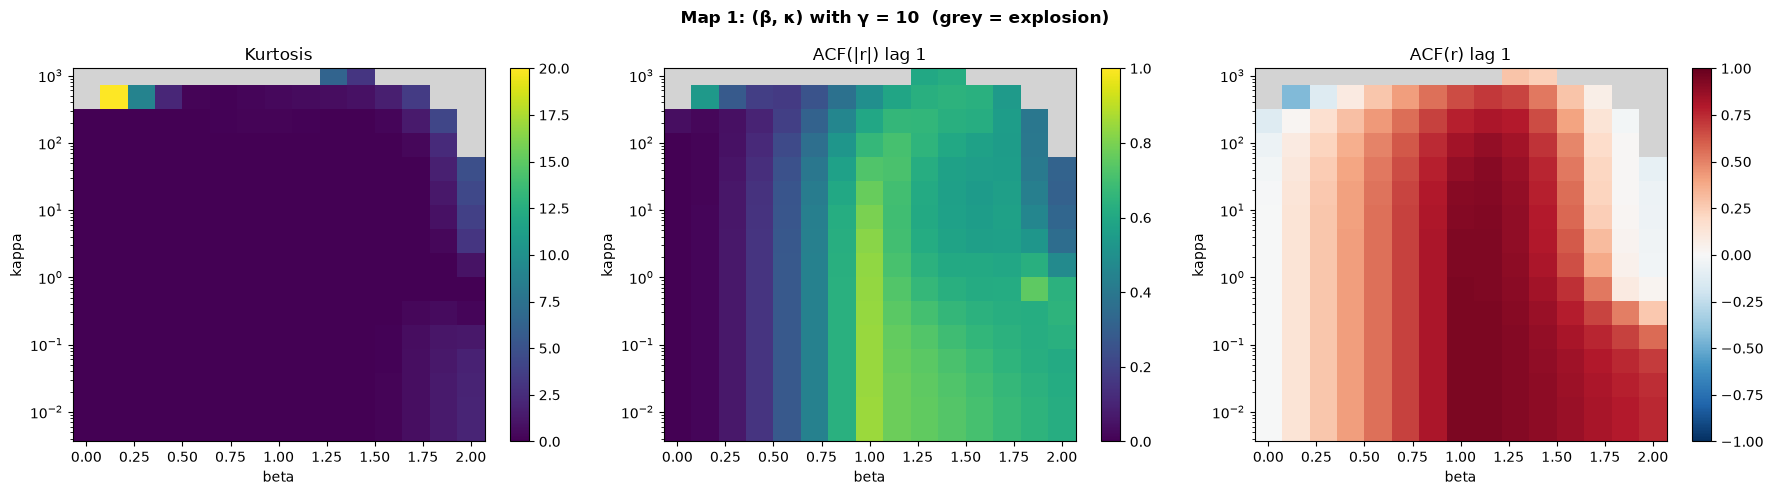

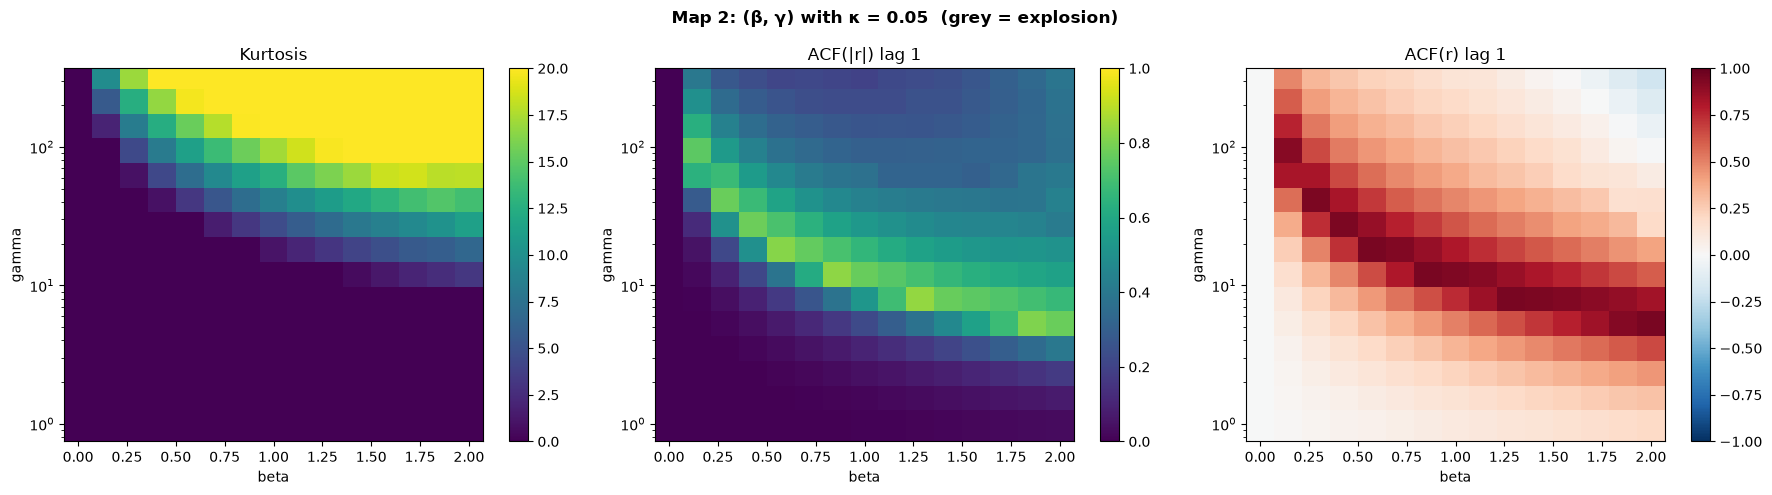

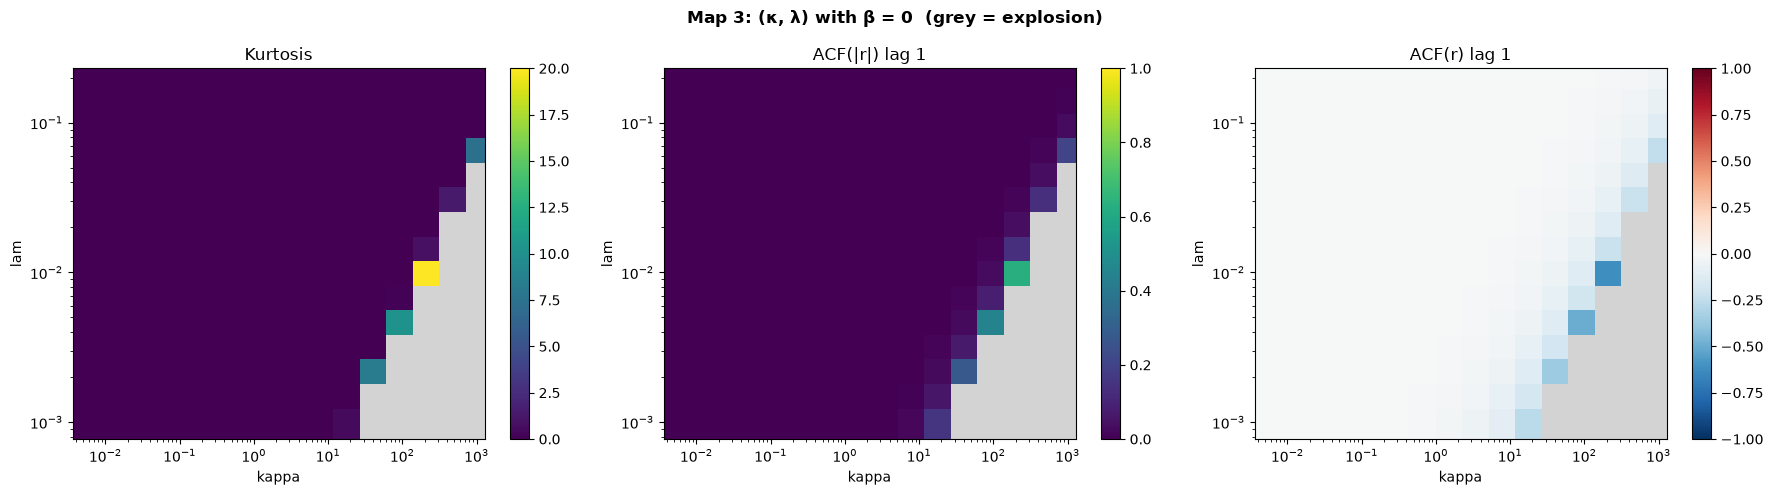

In [8]:
from scipy.stats import kurtosis

from abm import acf


def averaged_stats(theta, n_seeds=5, T=5000):
    """Kurtosis, lag-1 ACF of |r| and lag-1 ACF of r, averaged over seeds. NaN if any run explodes."""
    results = []
    for seed in range(n_seeds):
        p_s, _, _ = chiarella(**theta, T=T, rng=np.random.default_rng(seed))
        if np.isnan(p_s).any():  # explosion
            return [np.nan, np.nan, np.nan]
        r_s = np.diff(p_s)
        results.append([kurtosis(r_s), acf(np.abs(r_s), 1), acf(r_s, 1)])
    return np.mean(results, axis=0)


def sweep(name_x, values_x, name_y, values_y, fixed):
    """The 3 statistics on the (x, y) grid. Returns an array (3, len(y), len(x))."""
    grid = np.zeros((3, len(values_y), len(values_x)))
    for i, y in enumerate(values_y):
        for j, x in enumerate(values_x):
            grid[:, i, j] = averaged_stats({**theta0, **fixed, name_x: x, name_y: y})
    return grid


def plot_maps(grid, name_x, values_x, name_y, values_y, title, log_x=False, log_y=False):
    """Three heatmaps side by side; grey cells = at least one explosion."""
    settings = [("Kurtosis", "viridis", 0, 20), ("ACF(|r|) lag 1", "viridis", 0, 1), ("ACF(r) lag 1", "RdBu_r", -1, 1)]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for k, (stat_name, cmap, vmin, vmax) in enumerate(settings):
        ax = axes[k]
        cmap = plt.get_cmap(cmap).copy()
        cmap.set_bad("lightgrey")
        im = ax.pcolormesh(values_x, values_y, np.ma.masked_invalid(grid[k]), cmap=cmap, vmin=vmin, vmax=vmax,
                           shading="nearest")
        fig.colorbar(im, ax=ax)
        if log_x:
            ax.set_xscale("log")
        if log_y:
            ax.set_yscale("log")
        ax.set_xlabel(name_x)
        ax.set_ylabel(name_y)
        ax.set_title(stat_name)
    fig.suptitle(title + "  (grey = explosion)", fontweight="bold")
    plt.tight_layout()
    plt.show()


N = 15
betas = np.linspace(0, 2, N)
kappas = np.logspace(-2, 3, N)
gammas = np.logspace(0, 2.5, N)    # from 1 to ~300
lams = np.logspace(-3, -0.7, N)    # from 0.001 to 0.2

map1 = sweep("beta", betas, "kappa", kappas, fixed={"gamma": 10})
plot_maps(map1, "beta", betas, "kappa", kappas, "Map 1: (β, κ) with γ = 10", log_y=True)

map2 = sweep("beta", betas, "gamma", gammas, fixed={"kappa": 0.05})
plot_maps(map2, "beta", betas, "gamma", gammas, "Map 2: (β, γ) with κ = 0.05", log_y=True)

map3 = sweep("kappa", kappas, "lam", lams, fixed={"beta": 0})
plot_maps(map3, "kappa", kappas, "lam", lams, "Map 3: (κ, λ) with β = 0", log_x=True, log_y=True)

**Reading the maps.**
- **Map 1**: explosions at large κ; just before the frontier, strongly negative ACF(r) (the cubic term over-corrects: zig-zags); for βγα ≳ 0.37 the chartists' momentum becomes oscillatory.
- **Map 2**: no explosion (tanh is bounded). Fat tails appear only at large γ, when tanh acts as an on/off **switch**: chartists flip their whole position at once, creating rare huge jumps.
- **Map 3**: fundamentalists alone do nothing until a sharp explosion frontier κ ∝ λ/σ²; fat tails only appear in a thin band before it, together with unrealistic zig-zags.

## 1.3 Comparison with the S&P 500

Does the model reproduce the **stylized facts** of real returns (fat tails, volatility clustering, no linear autocorrelation)? Daily S&P 500, 2010–2026.

In [9]:
sp500 = pd.read_csv("../data/sp500_daily.csv", index_col="date", parse_dates=True)
r_sp = np.log(sp500["adj_close"]).diff().dropna()
r_sp.describe()

count    4217.000000
mean        0.000458
std         0.010830
min        -0.127652
25%        -0.003819
50%         0.000690
75%         0.005694
max         0.090895
Name: adj_close, dtype: float64

**Volatility clustering.** Large moves come in bursts (2011, 2020, 2022…). The ACF of r stays near 0 (direction is unpredictable), while the ACF of |r| stays positive for about 80 days (the **size** of moves is partly predictable). No realistic regime of the model reproduces this.

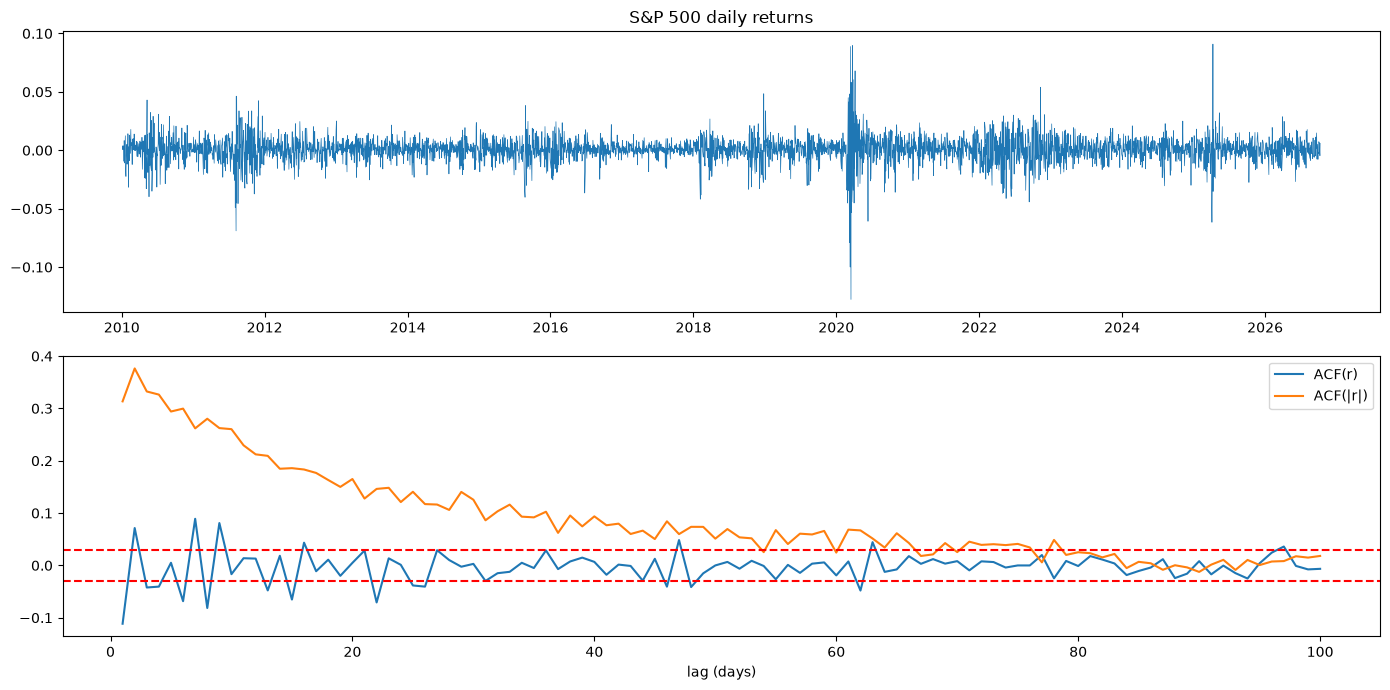

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
axes[0].plot(r_sp.index, r_sp.values, lw=0.5)
axes[0].set_title("S&P 500 daily returns")

lags = range(1, 101)
axes[1].plot(lags, [acf(r_sp.values, k) for k in lags], label="ACF(r)")
axes[1].plot(lags, [acf(np.abs(r_sp.values), k) for k in lags], label="ACF(|r|)")
band = 1.96 / np.sqrt(len(r_sp))
axes[1].axhline(band, color="red", ls="--")
axes[1].axhline(-band, color="red", ls="--")
axes[1].set_xlabel("lag (days)")
axes[1].legend()
plt.tight_layout()
plt.show()

**Comparison table.** The S&P 500 at three time scales, against the model at `theta0` and in the "switch" regime (β = 0.25, γ = 300).

In [11]:
def stylized_facts(r):
    return {
        "n": len(r),
        "std": np.std(r),
        "kurtosis": kurtosis(r),
        "ACF(r) lag 1": acf(r, 1),
        "ACF(|r|) lag 1": acf(np.abs(r), 1),
        "max |r|": np.abs(r).max(),
    }


log_price = np.log(sp500["adj_close"])
rows = {
    "S&P 500 daily": stylized_facts(log_price.diff().dropna().values),
    "S&P 500 weekly": stylized_facts(log_price.resample("W").last().diff().dropna().values),
    "S&P 500 monthly": stylized_facts(log_price.resample("ME").last().diff().dropna().values),
}
regimes = {"Chiarella theta0": theta0, "Chiarella switch": {**theta0, "beta": 0.25, "gamma": 300}}
for name, theta in regimes.items():
    p_regime, _, _ = chiarella(**theta, T=5000, rng=np.random.default_rng(0))   # separate name: do not overwrite p
    rows[name] = stylized_facts(np.diff(p_regime))

pd.DataFrame(rows).T.round(4)

,n,std,kurtosis,ACF(r) lag 1,ACF(|r|) lag 1,max |r|
S&P 500 daily,4217.0,0.0108,13.5179,-0.1115,0.3135,0.1277
S&P 500 weekly,874.0,0.0224,6.0993,-0.0911,0.2843,0.1623
S&P 500 monthly,201.0,0.0412,0.7069,-0.1260,0.2291,0.1337
Chiarella theta0,4999.0,0.0030,-0.1345,0.0477,-0.0257,0.0098
Chiarella switch,4999.0,0.0735,14.7676,0.3830,0.3171,0.3834


### Conclusion of Part 1

- At realistic parameters, the model produces **near Gaussian white noise**: no fat tails, no volatility clustering. The cause is structural: the noise has constant variance, and nothing in the model makes volatility vary over time.
- Its only non-linear mechanisms (tanh switch, cubic over-correction) produce fat tails with **unrealistic** features: returns 25 times too large, or strong zig-zags. In particular, nothing can generate the long memory of S&P 500 volatility (ACF(|r|) significant over ≈ 80 days).
- Aggregating daily → monthly returns brings the S&P 500 kurtosis from 13.5 to 0.7: monthly returns are almost Gaussian. The model, with Gaussian noise, fits that scale — consistent with its original calibration on monthly data (Majewski et al., 2020).